In [1]:
import access
import geopandas as gpd
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

In [2]:
# import the SVI data and cut it to just cook county
pop = gpd.read_file("../data/svi/SVI2018_US_tract.shp")
pop = pop[pop["STCNTY"] == "17031"]
pop = pop.to_crs("EPSG:4326")
print(len(pop))
pop.head()

1318


,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,F_THEME4,F_TOTAL,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry
184,17,ILLINOIS,IL,17031,Cook,17031381700,"Census Tract 3817, Cook County, Illinois",0.075986,0,11,...,-999,-999,0,11,-999.0,-999.0,551,0.000021,0.020359,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
185,17,ILLINOIS,IL,17031,Cook,17031980000,"Census Tract 9800, Cook County, Illinois",7.679554,0,11,...,-999,-999,0,11,-999.0,-999.0,38202,0.002171,0.222431,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
186,17,ILLINOIS,IL,17031,Cook,17031980100,"Census Tract 9801, Cook County, Illinois",1.151272,0,11,...,-999,-999,0,11,-999.0,-999.0,6449,0.000323,0.076961,"POLYGON ((-87.76230 41.79274, -87.75251 41.792..."
12180,17,ILLINOIS,IL,17031,Cook,17031020100,"Census Tract 201, Cook County, Illinois",0.158747,3836,361,...,0,0,569,245,14.8,6.3,3714,0.000044,0.027301,"POLYGON ((-87.69020 42.01682, -87.69020 42.017..."
12181,17,ILLINOIS,IL,17031,Cook,17031020200,"Census Tract 202, Cook County, Illinois",0.479524,6739,510,...,0,1,628,396,9.3,6.0,3249,0.000135,0.051852,"POLYGON ((-87.70875 42.01550, -87.70866 42.019..."


In [3]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
hos = hos.to_crs("EPSG:4326")
print(len(hos))
hos.head()

66


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.89140)



chi_times: Cost matrix with travel times from each Chicago Census Tract to all others.

chi_doc: Doctor and dentist counts for each Chicago Census Tract.

chi_pop: Population counts for each Chicago Census Tract.

chi_doc_geom: Doctor and dentist counts for each Chicago Census Tract along with geometric representations for Census Tracts.

chi_pop_geom: Population counts for each Chicago Census Tract along with geometric representations for Census Tracts.

chi_euclidean: Euclidean distance cost matrix with distances from each demand Chicago Census Tract to all others.

chi_euclidean_neighbors: Euclidean distance cost matrix with distances from each supply Census Tract to all others.

cook_county_hospitals: Contains data for each hospital location in Cook County including X Y coordinates.

cook_county_hospitals_geom: Contains data for each hospital location in Cook County including X Y coordinates, and geometric points for each hospital.

cook_county_tracts: Geometric representation of 

,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,geoid,geometry
0,1400000US17031440300,17,031,440300,4403,Tract,0.499,17031440300,"POLYGON ((-87.61467 41.74198, -87.61462 41.740..."
1,1400000US17031440600,17,031,440600,4406,Tract,0.259,17031440600,"POLYGON ((-87.61453 41.73650, -87.61450 41.735..."
2,1400000US17031440700,17,031,440700,4407,Tract,0.126,17031440700,"POLYGON ((-87.60967 41.73658, -87.60725 41.736..."
3,1400000US17031460200,17,031,460200,4602,Tract,0.232,17031460200,"POLYGON ((-87.55276 41.74464, -87.55150 41.744..."
4,1400000US17031460600,17,031,460600,4606,Tract,0.101,17031460600,"POLYGON ((-87.55629 41.73732, -87.55558 41.737..."


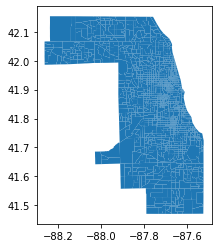

In [4]:
# load the census tracts from access package
access.Datasets.available_datasets()
cook_ct = access.Datasets.load_data("cook_county_tracts")
cook_ct = cook_ct.to_crs("EPSG:4326")
cook_ct["geoid"] = cook_ct["geoid"].astype(str)
cook_ct.plot()
cook_ct.head()

In [5]:
# join the hospitals to nearest census tract
hospitals_ct = gpd.sjoin(hos, cook_ct, how="inner", predicate="intersects")
hospitals_ct["geoid"] = hospitals_ct["geoid"].astype(str)
hospitals_ct.head()

,OBJECTID,ID,NAME_left,ADDRESS,CITY,STATE_left,ZIP,ZIP4,TELEPHONE,TYPE,...,geometry,index_right,GEO_ID,STATE_right,COUNTY_right,TRACT,NAME_right,LSAD,CENSUSAREA,geoid
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,POINT (-87.76746 41.86633),1105,1400000US17031831400,17,031,831400,8314,Tract,0.812,17031831400
4436,492,0004160644,LORETTO HOSPITAL,645 SOUTH CENTRAL AVE,CHICAGO,IL,60644,NOT AVAILABLE,(773) 626-4300,GENERAL ACUTE CARE,...,POINT (-87.76409 41.87212),1105,1400000US17031831400,17,031,831400,8314,Tract,0.812,17031831400
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,POINT (-87.67704 41.87074),1193,1400000US17031838200,17,031,838200,8382,Tract,0.447,17031838200
3080,4116,0007360612,UNIVERSITY OF ILLINOIS HOSPITAL,"1740 WEST TAYLOR ST, SUITE 1400",CHICAGO,IL,60612,NOT AVAILABLE,(312) 996-3900,GENERAL ACUTE CARE,...,POINT (-87.67052 41.86967),1193,1400000US17031838200,17,031,838200,8382,Tract,0.447,17031838200
4440,496,0006260612,JOHN H STROGER JR HOSPITAL,1901 W HARRISON ST,CHICAGO,IL,60612,NOT AVAILABLE,(312) 864-6000,GENERAL ACUTE CARE,...,POINT (-87.67440 41.87233),1193,1400000US17031838200,17,031,838200,8382,Tract,0.447,17031838200


In [6]:
# get car travel times
car = pd.read_csv("../data/travel_times/17031-output-TRACT-CAR.csv")
car["origin"] = car["origin"].astype(str)
car["destination"] = car["destination"].astype(str)
car.head()

,origin,destination,minutes
0,17031010100,17007010100,101.35
1,17031010100,17007010200,96.10
2,17031010100,17007010300,96.43
3,17031010100,17007010400,96.17
4,17031010100,17007010500,107.13


In [7]:
def get_spatial_units(pop, su_id, demand_field):
    """Gets the spatial units from the population data"""
    spatial_units = pop[[su_id, demand_field, "geometry"]].copy(deep=True)
    spatial_units = spatial_units.rename(columns={su_id: "GEOID", demand_field: "Demand"})
    return spatial_units.set_index('GEOID', drop=True)

In [8]:
spatial_units_df = get_spatial_units(pop, "FIPS", "E_TOTPOP")

In [9]:
spatial_units_df.head()

,Demand,geometry
GEOID,,
17031381700,0,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
17031980000,0,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
17031980100,0,"POLYGON ((-87.76230 41.79274, -87.75251 41.792..."
17031020100,3836,"POLYGON ((-87.69020 42.01682, -87.69020 42.017..."
17031020200,6739,"POLYGON ((-87.70875 42.01550, -87.70866 42.019..."


In [10]:
def aggregate_resources_to_spatial_units(resources, supply_field, spatial_units):
    """Takes a GeoDataFrame of resources and spatially joins to spatial units, then aggregates the values giving us a lookup of GEOID -> number of resources"""
    resources = resources[resources[supply_field] >= 0]
    joined = gpd.sjoin(spatial_units, resources, how="inner", predicate="intersects")
    joined = joined[[supply_field, "geometry"]]
    joined = joined.rename(columns={supply_field: "Supply"})
    return joined.dissolve(by="GEOID", aggfunc="sum")

In [11]:
resources = aggregate_resources_to_spatial_units(hos, "BEDS", spatial_units_df)
print(f"There are {len(resources)} hospital agents with {sum(resources['Supply'])} beds total")
resources.head()

There are 59 hospital agents with 18259 beds total


,geometry,Supply
GEOID,,
17031031000,"POLYGON ((-87.67441 41.97610, -87.66961 41.976...",189
17031031300,"POLYGON ((-87.65499 41.97640, -87.65428 41.976...",115
17031031400,"POLYGON ((-87.65012 41.96916, -87.64964 41.969...",184
17031032100,"POLYGON ((-87.65634 41.96176, -87.65475 41.961...",134
17031040300,"POLYGON ((-87.70582 41.98309, -87.70401 41.983...",279


In [12]:
def generate_agents_from_pop_data(pop_data, id_field, pop_field, pop_per_agent):
    """Generates a set of agents based on population data."""
    agent_data = []
    pop_data = pop_data.drop_duplicates(subset=[id_field])
    agent_counter = 0
    for index, row in pop_data.iterrows():
        # get this row's ID
        _id = str(row[id_field])
        # get the pop data for that locale.
        # Add one so that no location has no agents
        pop_num = float(row[pop_field]) + 1
        # determine number of agents in this locale
        num_agents = math.ceil(pop_num / pop_per_agent)
        for agent in range(num_agents):
            agent_data.append([agent_counter, _id])
            agent_counter += 1
    return pd.DataFrame(agent_data, columns=["ID", "GEOID"])

In [13]:
sum(pop["E_TOTPOP"])

5223719

In [14]:
agent_df = generate_agents_from_pop_data(pop, "FIPS", "E_TOTPOP", 100)

In [15]:
agent_df.head()

,ID,GEOID
0,0,17031381700
1,1,17031980000
2,2,17031980100
3,3,17031020100
4,4,17031020100


In [16]:
print(len(agent_df))

52895


In [17]:
car.head()

,origin,destination,minutes
0,17031010100,17007010100,101.35
1,17031010100,17007010200,96.10
2,17031010100,17007010300,96.43
3,17031010100,17007010400,96.17
4,17031010100,17007010500,107.13


In [18]:
x = car.set_index(["origin", "destination"])
x.head()

minutes
origin      destination         
17031010100 17007010100   101.35
            17007010200    96.10
            17007010300    96.43
            17007010400    96.17
            17007010500   107.13

In [19]:
x.loc[('17031010100', '17007010200')]

minutes    96.1
Name: (17031010100, 17007010200), dtype: float64

In [20]:
y = x["minutes"]
y

origin       destination
17031010100  17007010100    101.35
             17007010200     96.10
             17007010300     96.43
             17007010400     96.17
             17007010500    107.13
                             ...  
17031980100  55133203902    134.10
             55133204002    150.22
             55133204003    157.27
             55133204004    160.07
             55133204100    155.53
Name: minutes, Length: 3780024, dtype: float64

In [21]:
y[('17031010100', '17007010200')]

96.1

In [22]:
car[(car["origin"] == '17031010100') & (car["destination"] == '17031817500')]

,origin,destination,minutes
999,17031010100,17031817500,51.23


In [23]:
y['17031010100', '17031817500']

51.23

In [24]:
# get the IDs for the origins (all census tracts) and destinations (hospitals)
# def get_travel_dict(origins, destinations, travel_times, time_field="minutes"):
#     travel_dict = dict()
#     # only keep data for our destinations to speed up look-up
#     _travel_times = travel_times[travel_times["destination"].isin(destinations)]
#     for origin in tqdm(origins, desc="Getting travel times", position=0):
#     # for origin in origins:
#         # get just the times for the current origin
#         origin_times = _travel_times[_travel_times["origin"] == origin]
#         travel_dict[origin] = dict()
#         for dest in destinations:
#             # grab the time for origin -> destination
#             time = float(origin_times[origin_times["destination"] == dest][time_field])
#             # print(f"o: {origin}, d: {dest}, t: {time}")
#             travel_dict[origin][dest] = time
#     return travel_dict
def get_travel_dict(origins, destinations, travel_times, time_field="minutes"):
    travel_times = travel_times.copy(deep=True)
    travel_times = travel_times[travel_times["origin"].isin(origins)]
    travel_times = travel_times[travel_times["destination"].isin(destinations)]
    travel_times = travel_times.set_index(["origin", "destination"])
    return travel_times["minutes"]

In [25]:
origins = list(set(agent_df["GEOID"]))
dests = list(resources.index)

In [26]:
tdict = get_travel_dict(origins, dests, car)

In [27]:
tdict.head()

origin       destination
17031010100  17031031000    21.53
             17031031300    21.02
             17031031400    21.70
             17031032100    22.13
             17031040300    19.10
Name: minutes, dtype: float64

In [28]:
def choose_resources_gravity(agents, resources, travel_dict, time_step, memory=0, top_k=3):
    """Chooses the resource for each agent randomly using gravity models as probability"""
    locations = list(set(agents["GEOID"]))
    choice_field = f"Choice {time_step}"
    agents[choice_field] = ""
    # for geoid in tqdm(locations, desc="Agents choosing", position=0, total=len(locations)):
    for geoid in locations:
        resource_probabilities = []
        for index, row in resources.iterrows():
            supply = float(row["Supply"])
            if time_step > 0:
                # supply = float(row[f"Ratio {time_step-1}"])
                supply = float(np.mean([row[f"Ratio {ts}"] for ts in range(max(0, time_step))]))
                if memory > 0:
                    supply = float(np.mean([row[f"Ratio {ts}"] for ts in range(max(0, time_step-memory), time_step)]))
            # add the small number to avoid division by zero
            time = tdict[geoid, index] + 0.5
            resource_probabilities.append(supply / (time ** 2))
        resource_probabilities = np.asarray(resource_probabilities)
        # print(resource_probabilities)
        resources_to_consider = resources.index
        if top_k >= 0:
            # get the top k options
            ind = np.argpartition(resource_probabilities, -top_k)[-top_k:]
            resources_to_consider = resources.index[ind]
            resource_probabilities = resource_probabilities[ind]
        # print(resource_probabilities)
        resource_probabilities = resource_probabilities / sum(resource_probabilities)
        # print(resource_probabilities)
        agents_here = agents[agents["GEOID"] == geoid].index
        for a_index in agents_here:
            agents.at[a_index, choice_field] = np.random.choice(resources_to_consider, p=resource_probabilities)
    return agents

In [29]:
# agent_df = choose_resources_gravity(agent_df, resources, tdict, top_k=3)

In [30]:
# agent_df.head()

In [31]:
# resources.head()

In [32]:
def calculate_supply_demand_ratio(agents, resources, time):
    """Calculates the supply/demand ratio for a given time step"""
    choice, demand, ratio = f"Choice {time}", f"Demand {time}", f"Ratio {time}"
    utilization = agents.groupby([choice])["ID"].count()
    # drop the columns if they exist
    resources = resources.drop(columns=[demand, ratio], errors="ignore")
    resources = resources.merge(utilization.rename(demand).to_frame(), how="left", left_on="GEOID", right_index=True)
    resources[demand] = resources[demand].fillna(0)
    # add one to avoid division by zero
    resources[ratio] = resources["Supply"] / (resources[demand] + 1)
    return resources

In [33]:
# resources = calculate_supply_demand_ratio(agent_df, resources, supply_field="Supply")

In [34]:
# resources.head()

In [35]:
def calculate_mean_ratio_spatial_unit(agents, resources, spatial_units, time):
    """Calculate the average supply/demand ratio for each spatial unit"""
    choice_field, ratio_field = f"Choice {time}", f"Ratio {time}"
    choices = agent_df[["GEOID", choice_field]].merge(resources[[ratio_field]], left_on=choice_field, right_index=True)
    mean_ratio = choices.groupby("GEOID")[ratio_field].mean()
    spatial_units = spatial_units.merge(mean_ratio.rename(ratio_field).to_frame(), how="left", left_index=True, right_index=True)
    spatial_units[ratio_field] = spatial_units[ratio_field].fillna(0)
    return spatial_units

In [36]:
# choices = agent_df[["GEOID", "Choice 0"]].merge(resources[["Ratio 0"]], left_on="Choice 0", right_index=True)
# print(len(choices))
# choices.head()

In [37]:
# y = choices.groupby("GEOID")["Ratio 0"].mean()
# y.to_frame()

In [38]:
# spatial_units_df = calculate_mean_ratio_spatial_unit(agent_df, resources, spatial_units_df)

In [39]:
# spatial_units_df.head()

In [40]:
# spatial_units_df.plot(column="Ratio 0", legend=True, figsize=(10, 10))

In [41]:
def mean_time_to_resource(agents, spatial_units, travel_dict, time):
    """Calculates the average time to a resource for the agents in each spatial unit"""
    choice_field, time_field = f"Choice {time}", f"Time {time}"
    choices = agent_df[["GEOID", choice_field]].merge(travel_dict.to_frame()[["minutes"]], left_on=["GEOID", choice_field], right_index=True)
    mean_time = choices.groupby("GEOID")["minutes"].mean()
    spatial_units = spatial_units.merge(mean_time.rename(time_field).to_frame(), how="left", left_index=True, right_index=True)
    spatial_units[time_field] = spatial_units[time_field].fillna(0)
    return spatial_units

In [42]:
# choices = agent_df[["GEOID", "Choice 0"]].merge(tdict.to_frame()[["minutes"]], left_on=["GEOID", "Choice 0"], right_index=True)
# choices.head()

In [43]:
# y = choices.groupby("GEOID")["minutes"].mean()
# y.to_frame().head()

In [44]:
# spatial_units_df = mean_time_to_resource(agent_df, spatial_units_df, tdict)

In [45]:
# spatial_units_df.head()

In [46]:
# spatial_units_df.plot(column="Time 0", legend=True, figsize=(10,10))

In [47]:
# spatial_units_df["Product 0"] = spatial_units_df["Ratio 0"] * spatial_units_df["Time 0"]

In [48]:
# spatial_units_df.plot(column="Product 0", figsize=(10,10), legend=True)

In [49]:
def time_step(agents, resources, spatial_units, travel_dict, time=0):
    """Runs a full time step of the model"""
    agents = choose_resources_gravity(agents, resources, travel_dict, time)
    resources = calculate_supply_demand_ratio(agents, resources, time=time)
    spatial_units = calculate_mean_ratio_spatial_unit(agents, resources, spatial_units,  time=time)
    spatial_units = mean_time_to_resource(agents, spatial_units, travel_dict,  time=time)
    return agents, resources, spatial_units

In [50]:
time_steps = 10

In [51]:
for ts in tqdm(range(time_steps)):
    agent_df, resources, spatial_units_df = time_step(agent_df, resources, spatial_units_df, tdict, time=ts)

100%|██████████| 10/10 [03:58<00:00, 23.84s/it]


In [52]:
resources.head()

,geometry,Supply,Demand 0,Ratio 0,Demand 1,Ratio 1,Demand 2,Ratio 2,Demand 3,Ratio 3,...,Demand 5,Ratio 5,Demand 6,Ratio 6,Demand 7,Ratio 7,Demand 8,Ratio 8,Demand 9,Ratio 9
GEOID,,,,,,,,,,,,,,,,,,,,,
17031031000,"POLYGON ((-87.67441 41.97610, -87.66961 41.976...",189,378,0.498681,407,0.463235,152,1.235294,300,0.627907,...,395,0.477273,412,0.457627,424,0.444706,432,0.436490,476,0.396226
17031031300,"POLYGON ((-87.65499 41.97640, -87.65428 41.976...",115,131,0.871212,662,0.173454,111,1.026786,166,0.688623,...,219,0.522727,238,0.481172,232,0.493562,301,0.380795,284,0.403509
17031031400,"POLYGON ((-87.65012 41.96916, -87.64964 41.969...",184,95,1.916667,2543,0.072327,127,1.437500,193,0.948454,...,247,0.741935,286,0.641115,266,0.689139,276,0.664260,314,0.584127
17031032100,"POLYGON ((-87.65634 41.96176, -87.65475 41.961...",134,183,0.728261,551,0.242754,126,1.055118,218,0.611872,...,249,0.536000,301,0.443709,310,0.430868,306,0.436482,296,0.451178
17031040300,"POLYGON ((-87.70582 41.98309, -87.70401 41.983...",279,1038,0.268527,432,0.644342,202,1.374384,446,0.624161,...,593,0.469697,629,0.442857,628,0.443561,677,0.411504,726,0.383769


In [53]:
spatial_units_df.head()

,Demand,geometry,Ratio 0,Time 0,Ratio 1,Time 1,Ratio 2,Time 2,Ratio 3,Time 3,...,Ratio 5,Time 5,Ratio 6,Time 6,Ratio 7,Time 7,Ratio 8,Time 8,Ratio 9,Time 9
GEOID,,,,,,,,,,,,,,,,,,,,,
17031381700,0,"POLYGON ((-87.62892 41.80919, -87.62608 41.809...",0.160596,19.630000,0.106838,11.500000,0.319079,19.630000,0.142182,12.650000,...,0.046168,19.100000,0.868831,18.250000,0.215345,12.650000,0.052283,19.100000,0.054551,19.100000
17031980000,0,"POLYGON ((-87.94025 42.00717, -87.93895 42.006...",0.223097,31.470000,0.007407,36.930000,0.139970,31.470000,0.040872,35.620000,...,0.046168,35.620000,0.604511,21.070000,0.050244,35.620000,0.052283,35.620000,0.497340,31.470000
17031980100,0,"POLYGON ((-87.76230 41.79274, -87.75251 41.792...",0.115381,26.280000,0.110866,20.050000,0.033697,26.280000,0.710909,24.130000,...,0.046168,26.280000,0.048583,26.280000,0.215345,18.380000,1.057483,25.370000,0.054551,26.280000
17031020100,3836,"POLYGON ((-87.69020 42.01682, -87.69020 42.017...",0.372842,8.987692,0.324622,8.901282,0.471210,25.116923,0.525877,17.230000,...,0.447489,12.221282,0.382485,16.631538,0.423497,12.221282,0.406349,11.339231,0.460317,14.016667
17031020200,6739,"POLYGON ((-87.70875 42.01550, -87.70866 42.019...",0.394777,12.113235,0.434218,14.300882,0.254642,30.397794,0.343605,25.676176,...,0.358276,20.597353,0.385920,20.209706,0.351651,22.478824,0.404162,19.128529,0.376238,19.398824


In [55]:
ratios = []
ratio_columns = [f"Ratio {x}" for x in range(time_steps)]
for index, row in resources.iterrows():
    ratios.append(list(row[ratio_columns]))

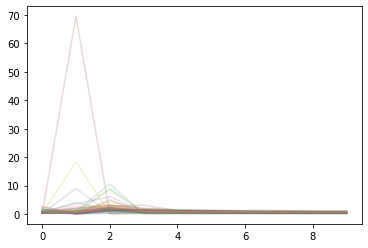

In [56]:
for i, index in enumerate(resources.index):
    plt.plot(range(time_steps), ratios[i], label=index, alpha=0.2)
ax = plt.gca()

In [57]:
ratios = []
ratio_columns = [f"Ratio {x}" for x in range(time_steps)]
for index, row in spatial_units_df.iterrows():
    ratios.append(list(row[ratio_columns]))

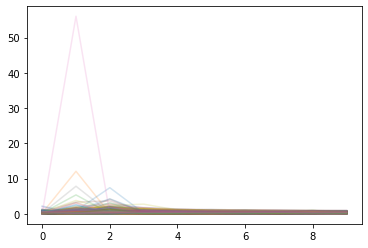

In [58]:
for i, index in enumerate(spatial_units_df.index):
    plt.plot(range(time_steps), ratios[i], label=index, alpha=0.2)

In [59]:
plt.show()

<AxesSubplot:>

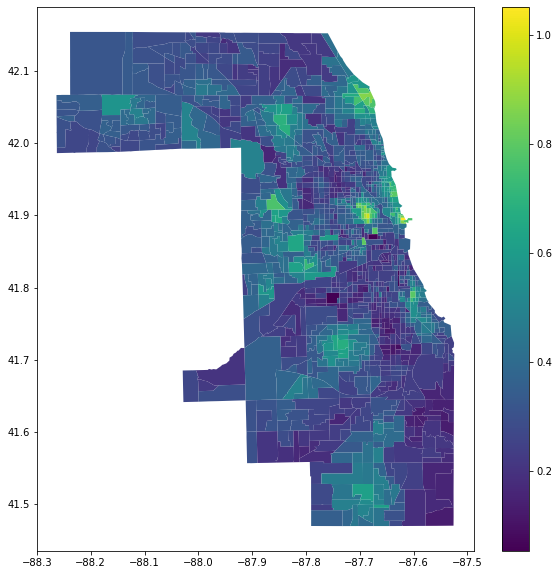

In [60]:
spatial_units_df.plot(column=f"Ratio {time_steps -1}", figsize=(10, 10), legend=True)

In [61]:
ratios = []
ratio_columns = [f"Time {x}" for x in range(time_steps)]
for index, row in spatial_units_df.iterrows():
    ratios.append(list(row[ratio_columns]))

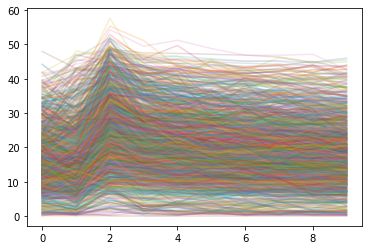

In [62]:
for i, index in enumerate(spatial_units_df.index):
    plt.plot(range(time_steps), ratios[i], label=index, alpha=0.2)

<AxesSubplot:>

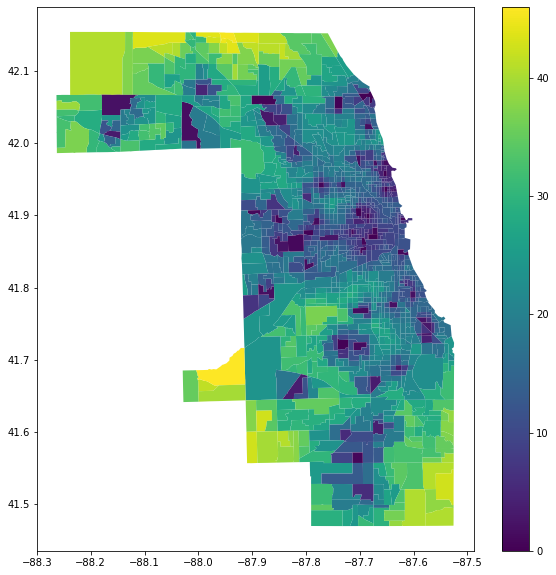

In [63]:
spatial_units_df.plot(column=f"Time {time_steps -1}", figsize=(10, 10), legend=True)

In [64]:
def normalize_columns(df, columns):
    for column in columns:
        df[column] = (df[column] - df[column].min()) / (df[column].max() - df[column].min())
    return df

<AxesSubplot:>

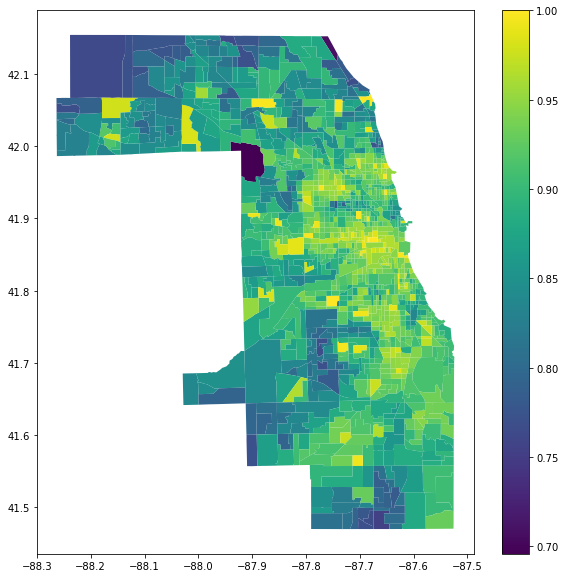

In [65]:
spatial_units_df = normalize_columns(spatial_units_df, [f"Time {time_steps -1}", f"Ratio {time_steps -1}"])
spatial_units_df["Product"] = (spatial_units_df[f"Time {time_steps -1}"] * spatial_units_df[f"Ratio {time_steps -1}"])
spatial_units_df["Product"] = 1 + (-1 * spatial_units_df["Product"])
spatial_units_df.plot(column="Product", figsize=(10, 10), legend=True)

In [66]:
spatial_units_df.head()

,Demand,geometry,Ratio 0,Time 0,Ratio 1,Time 1,Ratio 2,Time 2,Ratio 3,Time 3,...,Time 5,Ratio 6,Time 6,Ratio 7,Time 7,Ratio 8,Time 8,Ratio 9,Time 9,Product
GEOID,,,,,,,,,,,,,,,,,,,,,
17031381700,0,"POLYGON ((-87.62892 41.80919, -87.62608 41.809...",0.160596,19.630000,0.106838,11.500000,0.319079,19.630000,0.142182,12.650000,...,19.100000,0.868831,18.250000,0.215345,12.650000,0.052283,19.100000,0.000000,0.415200,1.000000
17031980000,0,"POLYGON ((-87.94025 42.00717, -87.93895 42.006...",0.223097,31.470000,0.007407,36.930000,0.139970,31.470000,0.040872,35.620000,...,35.620000,0.604511,21.070000,0.050244,35.620000,0.052283,35.620000,0.444726,0.684102,0.695762
17031980100,0,"POLYGON ((-87.76230 41.79274, -87.75251 41.792...",0.115381,26.280000,0.110866,20.050000,0.033697,26.280000,0.710909,24.130000,...,26.280000,0.048583,26.280000,0.215345,18.380000,1.057483,25.370000,0.000000,0.571280,1.000000
17031020100,3836,"POLYGON ((-87.69020 42.01682, -87.69020 42.017...",0.372842,8.987692,0.324622,8.901282,0.471210,25.116923,0.525877,17.230000,...,12.221282,0.382485,16.631538,0.423497,12.221282,0.406349,11.339231,0.407540,0.304697,0.875824
17031020200,6739,"POLYGON ((-87.70875 42.01550, -87.70866 42.019...",0.394777,12.113235,0.434218,14.300882,0.254642,30.397794,0.343605,25.676176,...,20.597353,0.385920,20.209706,0.351651,22.478824,0.404162,19.128529,0.323094,0.421696,0.863753


In [67]:
x = cook_ct.set_index("geoid")
x.head()

,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,geometry
geoid,,,,,,,,
17031440300,1400000US17031440300,17,031,440300,4403,Tract,0.499,"POLYGON ((-87.61467 41.74198, -87.61462 41.740..."
17031440600,1400000US17031440600,17,031,440600,4406,Tract,0.259,"POLYGON ((-87.61453 41.73650, -87.61450 41.735..."
17031440700,1400000US17031440700,17,031,440700,4407,Tract,0.126,"POLYGON ((-87.60967 41.73658, -87.60725 41.736..."
17031460200,1400000US17031460200,17,031,460200,4602,Tract,0.232,"POLYGON ((-87.55276 41.74464, -87.55150 41.744..."
17031460600,1400000US17031460600,17,031,460600,4606,Tract,0.101,"POLYGON ((-87.55629 41.73732, -87.55558 41.737..."


In [68]:
x = x.merge(spatial_units_df["Product"], left_index=True, right_index=True)
x.head()

,GEO_ID,STATE,COUNTY,TRACT,NAME,LSAD,CENSUSAREA,geometry,Product
17031440300,1400000US17031440300,17,031,440300,4403,Tract,0.499,"POLYGON ((-87.61467 41.74198, -87.61462 41.740...",0.932878
17031440600,1400000US17031440600,17,031,440600,4406,Tract,0.259,"POLYGON ((-87.61453 41.73650, -87.61450 41.735...",0.913187
17031440700,1400000US17031440700,17,031,440700,4407,Tract,0.126,"POLYGON ((-87.60967 41.73658, -87.60725 41.736...",0.917242
17031460200,1400000US17031460200,17,031,460200,4602,Tract,0.232,"POLYGON ((-87.55276 41.74464, -87.55150 41.744...",0.899953
17031460600,1400000US17031460600,17,031,460600,4606,Tract,0.101,"POLYGON ((-87.55629 41.73732, -87.55558 41.737...",0.922982


In [69]:
columns = ["Product", "gravity_BEDS"]
x = normalize_columns(x, columns)
x.head()

KeyError: 'gravity_BEDS'

In [ ]:
x = x[columns]
corr = x.corr()
corr.style.background_gradient(cmap='coolwarm')

In [ ]:
# calculate the gravity-based access
A = access.Access(
    demand_df=pop,
    demand_index="FIPS",
    demand_value="E_TOTPOP",
    supply_df=hospitals_ct,
    supply_index="geoid",
    supply_value="BEDS",
    cost_df=car,
    cost_origin="origin",
    cost_dest="destination",
    cost_name="minutes"
)

In [ ]:
gravity = access.weights.gravity(scale=60, alpha=-1, min_dist=1)
fn30 = access.weights.step_fn({10: 1, 20: 0.68, 30: 0.22})
fn60 = access.weights.step_fn({20: 1, 40: 0.68, 60: 0.22})
gaussian = access.weights.gaussian(20)

In [ ]:
{t : round(gravity(t), 2) for t in [0, 1, 2, 20, 40, 60]}

In [ ]:
A.weighted_catchment(name="gravity", weight_fn=gravity)
# A.fca_ratio(name="fca", max_cost=15)
# A.fca_ratio(name="fca", max_cost=30) 
# A.fca_ratio(name="fca60", max_cost=60)
# A.fca_ratio(name="fca90", max_cost=90)
A.two_stage_fca(name="2sfca", max_cost=60)
A.enhanced_two_stage_fca(name="2sfca30", weight_fn=fn30)
A.enhanced_two_stage_fca(name="2sfca60", weight_fn=fn60)
A.enhanced_two_stage_fca(name="g2sfca", weight_fn=gaussian)
A.three_stage_fca(name="3sfca")
# A.raam(name="raam", tau=60)
# A.raam(name="raam30", tau=30)

In [ ]:
A.access_df.head()

In [ ]:
gdf = cook_ct.merge(access_obj.access_df, left_on="geoid", right_on="FIPS")
gdf.head()

In [ ]:
access_field = "gravity_BEDS"
gdf.plot(column=access_field, figsize=(10,10), legend=True, vmin=gdf[access_field].quantile(0.05), vmax=gdf[access_field].quantile(0.95))